# Copula Monte Carlo: Gaussian and Student t, with their Monte Carlo errors

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the large-portfolio distribution and the fitted correlation)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- describe the illustrative book of the case and build it with the engine from its groups of identical names;
- simulate the loss of a finite book under a one-factor Gaussian copula, a two-sector Gaussian copula and a Student t copula, and read VaR, expected shortfall and capital from each sample;
- say what tail dependence is, and check on two names that the t copula puts several times more probability on a joint default than the Gaussian copula at the same correlation;
- read a Monte Carlo standard error, see how it shrinks with the number of scenarios, and say when a batch-means error in the far tail is not to be trusted;
- watch the Monte Carlo VaR of an N-name book converge to the large-portfolio quantile as N grows, and read the engine's convergence test.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the commercial and industrial file of case C10, `data/derived/C10/commercial-industrial.json` (owner: this repository; the loss rates behind its fit come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`). Three blocks matter here:

- `outputs.portfolio`: the **illustrative book**, constructed for the case from the fitted PD and correlation and never a bank's: three groups of identical names (20 large, 100 mid-size and 1,000 small), 100 million USD of exposure in all, an LGD of 45%, and a PD per group scaled so that the exposure-weighted PD is the fitted one. Licence class `illustrative`;
- `outputs.fit`: the fitted PD and correlation of notebook 02;
- `outputs.rungs`: the committed ladder, with each rung's measures and the number of scenarios and the seed of its Monte Carlo. Here we use the Gaussian, sector and Student t rungs, and `tests` for the committed convergence row.

The next cell loads the file, prints the groups and the concentration of the book, and prints how the committed rungs were simulated.

In [2]:
# Load the artifact, print the groups of the illustrative book and how the committed rungs were simulated
doc = json.loads((ROOT / "data" / "derived" / "C10" / "commercial-industrial.json").read_text(encoding="utf-8"))
out = doc["outputs"]
book = out["portfolio"]
ml = out["fit"]["maximum_likelihood"]
pd_hat, rho_hat = ml["pd"]["estimate"], ml["rho"]["estimate"]
rungs = {r["id"]: r for r in out["rungs"]}

print("book label:", book["label"], "| names:", book["n_names"], "| total exposure:", f"{book['total_ead']:,.0f}", book["currency"])
for g in book["groups"]:
    print(f"{g['id']:9s} {g['n_names']:5d} names x {g['ead_each']:>11,.0f} | PD {g['pd']:.5f} | LGD {g['lgd']} | loading {g['loading']:.4f} | sector {g['sector']}")
print("HHI:", book["hhi"], "| effective names:", round(book["effective_names"], 1), "| largest name share:", book["largest_share"])

print("baked by riskvalidation", doc["provenance"]["riskvalidation_version"])
for rid in ("c2-gaussian-1f", "c2-gaussian-mf", "c3-student-t"):
    print(rid, rungs[rid]["simulation"], [(p["name"], p["value"]) for p in rungs[rid]["parameters"]])

book label: illustrative | names: 1120 | total exposure: 100,000,000 USD
g-large      20 names x   2,000,000 | PD 0.00506 | LGD 0.45 | loading 0.2523 | sector core
g-mid       100 names x     400,000 | PD 0.01012 | LGD 0.45 | loading 0.2523 | sector core
g-small    1000 names x      20,000 | PD 0.01517 | LGD 0.45 | loading 0.2523 | sector periphery
HHI: 0.00964 | effective names: 103.7 | largest name share: 0.02
baked by riskvalidation 0.7.0
c2-gaussian-1f {'n_scenarios': 1000000, 'seed': 4001, 'chunk_size': 16741} [('rho', 0.0636765484), ('lgd', 0.45)]
c2-gaussian-mf {'n_scenarios': 1000000, 'seed': 4002, 'chunk_size': 16741} [('n_factors', 2.0), ('factor_correlation', 0.5), ('rho', 0.0636765484), ('lgd', 0.45)]
c3-student-t {'n_scenarios': 1000000, 'seed': 4003, 'chunk_size': 16741} [('nu', 5.0), ('rho', 0.0636765484), ('lgd', 0.45)]


## Method

### Step 1: the Gaussian copula and the loss of a finite book

The large-portfolio formulas of notebook 01 need infinitely many loans. A real book has a finite number of names with different exposures and PDs, so its loss is random even given the economy. The **Gaussian copula** model keeps the latent asset return of the one-factor model but lets every name have its own loading $\beta_i$ on a vector of systematic factors $Z\sim N(0,\Sigma)$ (Li, 2000, https://doi.org/10.3905/jfi.2000.319253):

$$A_i = \beta_i^\top Z + \sqrt{1-\beta_i^\top\beta_i}\,\varepsilon_i, \qquad D_i = \mathbf 1\{A_i < \Phi^{-1}(\mathrm{PD}_i)\}, \qquad L = \sum_i \mathrm{EAD}_i\,\mathrm{LGD}_i\,D_i$$

with one factor when every loading is $\sqrt\rho$. The loss has no closed form, so the engine simulates it: `portfolio_from_groups` expands the groups into names, and `simulate_gaussian` draws the scenarios with a seeded generator, so a run is reproducible for the same seed, number of scenarios and chunk size. From the sample, `measures_from_sample` returns the expected loss given by the book, the VaR as the sample quantile, the expected shortfall with the Acerbi and Tasche weights (https://doi.org/10.1016/S0378-4266(02)00283-2), the capital $\mathrm{VaR}-\mathrm{EL}$ and the batch-means standard errors. We use 100,000 scenarios here, a tenth of the committed run, and the seed and chunk size of the pipeline. The next cell builds the book and runs the one-factor copula.

In [3]:
# Build the book and simulate 100,000 scenarios of the one-factor Gaussian copula
from riskvalidation.portfolio import copula
from riskvalidation.portfolio import portfolio as pf

groups = book["groups"]
one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
print("names:", one.ead.size, "| factors:", one.loadings.shape[1], "| EL:", f"{el:,.0f}", "| committed EL:", f"{rungs['c2-gaussian-1f']['measures'][0]['el']:,.0f}")

N_SCENARIOS, CHUNK = 100_000, rungs["c2-gaussian-1f"]["simulation"]["chunk_size"]
sample_1f = copula.simulate_gaussian(one, N_SCENARIOS, rungs["c2-gaussian-1f"]["simulation"]["seed"], CHUNK)
measures_1f = pf.measures_from_sample(sample_1f.losses, (0.99, 0.999), el)

print(f"{'q':>6s} {'VaR':>12s} {'error std.':>10s} {'ES':>12s} {'capital':>12s} | {'committed VaR (1M)':>26s} {'error std.':>10s} {'z':>6s}")
for m, c in zip(measures_1f, rungs["c2-gaussian-1f"]["measures"]):
    z = (m.var - c["var"]) / math.hypot(m.var_se, c["var_se"])
    print(f"{m.level:6.3f} {m.var:12,.0f} {m.var_se:10,.0f} {m.es:12,.0f} {m.ec:12,.0f} | {c['var']:26,.0f} {c['var_se']:10,.0f} {z:6.2f}")

names: 1120 | factors: 1 | EL: 409,721 | committed EL: 409,721
     q          VaR error std.           ES      capital |         committed VaR (1M) error std.      z
 0.990    2,088,000     18,433    2,535,057    1,678,279 |                  2,097,000      4,792  -0.47
 0.999    3,087,000     54,340    3,609,180    2,677,279 |                  3,177,000     15,163  -1.60


A sample of 100,000 scenarios and one of 1,000,000 differ by Monte Carlo noise only, so the difference divided by the combined standard error, the last column, should be small: within about two. The committed run is the more precise of the two and is the reference. Next, a second source of dependence: names in different sectors.

In [4]:
# Build the two-sector book (core and periphery) and simulate it with the committed factor correlation
factor_rho = next(p["value"] for p in rungs["c2-gaussian-mf"]["parameters"] if p["name"] == "factor_correlation")
factor_corr = np.array([[1.0, factor_rho], [factor_rho, 1.0]])
multi = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], factor_corr=factor_corr, one_factor=False)
print("factors:", multi.loadings.shape[1], "| correlation between the two sector factors:", factor_rho)

sample_mf = copula.simulate_gaussian(multi, N_SCENARIOS, rungs["c2-gaussian-mf"]["simulation"]["seed"], CHUNK)
measures_mf = pf.measures_from_sample(sample_mf.losses, (0.99, 0.999), el)
for m1, mm, c in zip(measures_1f, measures_mf, rungs["c2-gaussian-mf"]["measures"]):
    print(f"q = {m1.level}: VaR one factor {m1.var:,.0f} | VaR two sectors {mm.var:,.0f} | committed two sectors (1M) {c['var']:,.0f}")

factors: 2 | correlation between the two sector factors: 0.5
q = 0.99: VaR one factor 2,088,000 | VaR two sectors 2,025,000 | committed two sectors (1M) 2,007,000
q = 0.999: VaR one factor 3,087,000 | VaR two sectors 2,988,000 | committed two sectors (1M) 3,033,000


With two sector factors correlated at 0.5 instead of one factor shared by every name, the periphery and the core no longer fall together every time, and the tail of the loss is thinner. The one-factor copula is the more conservative of the two on this book.

### Step 2: the Student t copula and tail dependence

The Gaussian copula has a known weakness: however high the correlation, extreme events in two names become independent far enough in the tail. The **Student t copula** divides the asset return by a common random scale, $A_i=\sqrt{W}\,(\beta_i^\top Z+\sqrt{1-\beta_i^\top\beta_i}\,\varepsilon_i)$ with $W=\nu/\chi^2_\nu$, and a name defaults when $A_i < t_\nu^{-1}(\mathrm{PD}_i)$ (Frey and McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta and McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x). The same $W$ multiplies every name, so a small $W$ makes all of them move together: this is **tail dependence**, and it raises the probability of a joint default for the same asset correlation. The marginal PD of every name is unchanged. The engine's `simulate_student_t` takes the degrees of freedom $\nu>2$; the committed rung uses $\nu=5$. The next cell simulates it and puts the three copulas side by side.

In [5]:
# Simulate the Student t copula with the committed degrees of freedom and compare the three copulas
nu = next(p["value"] for p in rungs["c3-student-t"]["parameters"] if p["name"] == "nu")
sample_t = copula.simulate_student_t(one, nu, N_SCENARIOS, rungs["c3-student-t"]["simulation"]["seed"], CHUNK)
measures_t = pf.measures_from_sample(sample_t.losses, (0.99, 0.999), el)
print("nu =", nu)

print(f"{'q':>6s} {'Gaussian 1F':>16s} {'Gaussian 2 sectors':>20s} {'Student t':>14s} {'t / Gaussian':>14s}")
for a, b, c in zip(measures_1f, measures_mf, measures_t):
    print(f"{a.level:6.3f} {a.var:16,.0f} {b.var:20,.0f} {c.var:14,.0f} {c.var / a.var:14.2f}")
committed_t = rungs["c3-student-t"]["measures"][-1]["var"] / rungs["c2-gaussian-1f"]["measures"][-1]["var"]
print("committed ratio at 99.9% (1M scenarios):", round(committed_t, 3), "| impact.var_999_student_t_over_gaussian:", round(doc["impact"]["var_999_student_t_over_gaussian"]["value"], 3))

nu = 5.0
     q      Gaussian 1F   Gaussian 2 sectors      Student t   t / Gaussian
 0.990        2,088,000            2,025,000      6,264,000           3.00
 0.999        3,087,000            2,988,000     13,815,000           4.48
committed ratio at 99.9% (1M scenarios): 4.122 | impact.var_999_student_t_over_gaussian: 4.122


The tail dependence can be checked on the smallest possible book, two names. For two names with the fitted PD and correlation, the engine's simulation gives the probability that both default; SciPy's bivariate normal and bivariate t distribution functions give the same probability in closed form, from the definition of the copulas. Independence would give $\mathrm{PD}^2$. The next cell uses 4 million scenarios of two names, which takes under a second.

In [6]:
# Probability that two names default together: engine simulation against SciPy's bivariate distributions
pair = pf.portfolio_from_groups(
    [{"id": "pair", "n_names": 2, "ead_each": 1_000_000.0, "pd": pd_hat, "lgd": 0.45, "loading": math.sqrt(rho_hat), "sector": "core"}],
    "USD", 0.25, one_factor=True)
scenarios = 4_000_000
one_name_loss = 1_000_000.0 * 0.45
pair_gauss = copula.simulate_gaussian(pair, scenarios, 11, 100_000)
pair_t = copula.simulate_student_t(pair, nu, scenarios, 12, 100_000)
both_gauss = float(np.mean(pair_gauss.losses > 1.5 * one_name_loss))
both_t = float(np.mean(pair_t.losses > 1.5 * one_name_loss))

corr = np.array([[1.0, rho_hat], [rho_hat, 1.0]])
# SciPy's bivariate t integrates with a random rule: a fixed seed and a million points make the value reproducible
exact_gauss = float(stats.multivariate_normal.cdf([stats.norm.ppf(pd_hat)] * 2, cov=corr, maxpts=1_000_000))
exact_t = float(stats.multivariate_t.cdf([stats.t.ppf(pd_hat, nu)] * 2, shape=corr, df=nu, maxpts=1_000_000, random_state=0))
print("PD:", round(pd_hat, 5), "| independent names: PD squared:", f"{pd_hat ** 2:.3e}")
print(f"Gaussian: engine {both_gauss:.3e} | SciPy {exact_gauss:.3e}")
print(f"Student t: engine {both_t:.3e} | SciPy {exact_t:.3e}")
print("joint default, Gaussian over independent (SciPy):", round(exact_gauss / pd_hat ** 2, 2))
print("joint default, t over Gaussian (SciPy):", round(exact_t / exact_gauss, 2))

PD: 0.0091 | independent names: PD squared: 8.290e-05
Gaussian: engine 1.385e-04 | SciPy 1.287e-04
Student t: engine 8.245e-04 | SciPy 8.049e-04
joint default, Gaussian over independent (SciPy): 1.55
joint default, t over Gaussian (SciPy): 6.26


The picture compares the tails. The next cell draws the probability that the loss exceeds each level, on a logarithmic axis, for the three samples, with the VaR levels marked. Where the curves part is where the models disagree about capital.

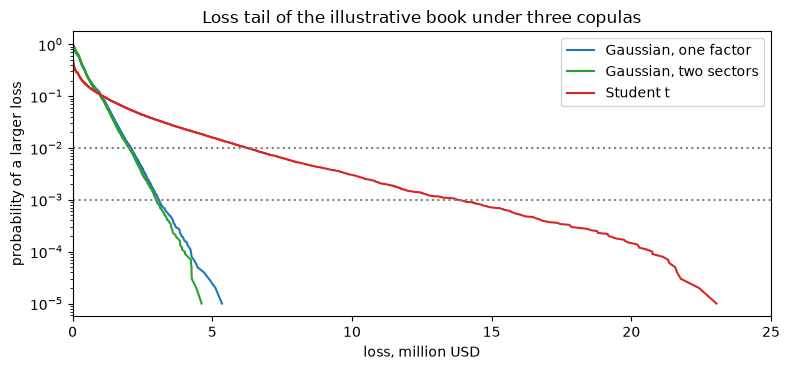

In [7]:
# Draw the exceedance probability of the loss for the three samples on a logarithmic axis
fig, ax = plt.subplots(figsize=(8, 3.8))
for sample, label, color in ((sample_1f, "Gaussian, one factor", "tab:blue"), (sample_mf, "Gaussian, two sectors", "tab:green"), (sample_t, "Student t", "tab:red")):
    ordered = np.sort(sample.losses)
    exceed = 1.0 - (np.arange(1, ordered.size + 1) / ordered.size)
    keep = exceed > 0
    ax.plot(ordered[keep] / 1e6, exceed[keep], label=label, color=color)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="gray", linestyle=":")
ax.set_yscale("log")
ax.set_xlim(0, 25)
ax.set_xlabel("loss, million USD")
ax.set_ylabel("probability of a larger loss")
ax.set_title("Loss tail of the illustrative book under three copulas")
ax.legend()
fig.tight_layout()
plt.show()

### Step 3: the Monte Carlo standard error

A Monte Carlo VaR is an estimate, and a validator needs to know how precise it is. The engine's `mc_standard_errors` splits the sample into consecutive batches (20 by default), computes VaR and ES in each, and reports the standard deviation of the batch estimates over $\sqrt{20}$; this estimator is a choice of the engine's contract, the research names none. The error should shrink like $1/\sqrt S$ with the number of scenarios $S$. The next cell takes the first 10,000, 25,000, 50,000 and 100,000 scenarios of the Gaussian sample and prints the standard errors at 99% and at 99.9%.

In [8]:
# Standard errors of VaR and ES at 99% and 99.9% for growing numbers of scenarios
from riskvalidation.portfolio.copula import mc_standard_errors

print(f"{'scenarios':>10s} {'SE of VaR 99%':>16s} {'SE of ES 99%':>16s} {'SE of VaR 99.9%':>18s} {'losses per batch':>20s}")
se_99, se_999 = {}, {}
for n in (10_000, 25_000, 50_000, 100_000):
    v99, e99 = mc_standard_errors(sample_1f.losses[:n], 0.99, 20)
    v999, _ = mc_standard_errors(sample_1f.losses[:n], 0.999, 20)
    se_99[n], se_999[n] = v99, v999
    print(f"{n:10,d} {v99:16,.0f} {e99:16,.0f} {v999:18,.0f} {n // 20:20,d}")
print("ratio of the 99% VaR errors, 10,000 to 100,000 scenarios:", round(se_99[10_000] / se_99[100_000], 2), "| sqrt(10) =", round(math.sqrt(10), 2))
print("ratio of the 99.9% VaR errors, 10,000 to 100,000 scenarios:", round(se_999[10_000] / se_999[100_000], 2))
print("tail scenarios in one batch of 5,000 at 99.9%:", round(5_000 * (1 - 0.999), 1))

 scenarios    SE of VaR 99%     SE of ES 99%    SE of VaR 99.9%     losses per batch
    10,000           67,701           62,462             97,473                  500
    25,000           40,518           50,757             79,648                1,250
    50,000           24,976           33,882             65,394                2,500
   100,000           18,433           24,792             54,340                5,000
ratio of the 99% VaR errors, 10,000 to 100,000 scenarios: 3.67 | sqrt(10) = 3.16
ratio of the 99.9% VaR errors, 10,000 to 100,000 scenarios: 1.79
tail scenarios in one batch of 5,000 at 99.9%: 5.0


### Step 4: convergence to the large-portfolio limit, and the engine's test

A finite book sits above the large-portfolio quantile by a granularity effect that fades as the number of names grows. For a book of $N$ identical names with the fitted PD and correlation, the Monte Carlo VaR should converge to the closed-form `lhp_quantile` of notebook 01. The engine's `mc_convergence` tests the estimate against an analytic anchor: the statistic is $(\text{estimate}-\text{anchor})/\mathrm{se}$ and the two-sided normal p-value is its p-value; it is a Contraste internal gate, green from 0.05 and red below 0.01, and it is meaningful only for a book close to the limit. The next cell simulates 50,000 scenarios for five sizes of book, from 20 to 5,000 names, on the same 100 million USD of exposure, and tests each against the anchor.

In [9]:
# Simulate books of 20 to 5,000 identical names and test each Monte Carlo VaR against the large-portfolio quantile
from riskvalidation.validation.portfolio import mc_convergence

anchor = pf.lhp_measures(book["total_ead"], book["lgd_mean"], pd_hat, rho_hat, (0.999,))[0].var
print("large-portfolio VaR at 99.9%:", f"{anchor:,.0f}")
print(f"{'names':>7s} {'MC VaR':>12s} {'error std.':>10s} {'VaR / anchor':>13s} {'p':>9s} light")
ratios = {}
for n_names in (20, 100, 500, 2000, 5000):
    identical = pf.portfolio_from_groups(
        [{"id": "g", "n_names": n_names, "ead_each": book["total_ead"] / n_names, "pd": pd_hat, "lgd": book["lgd_mean"], "loading": math.sqrt(rho_hat), "sector": "core"}],
        book["currency"], book["lgd_gamma"], one_factor=True)
    chunk = max(1000, min(100_000, 150_000_000 // (8 * n_names)))
    run = copula.simulate_gaussian(identical, 50_000, 4005, chunk)
    m = pf.measures_from_sample(run.losses, (0.999,), pf.expected_loss(identical))[0]
    verdict = mc_convergence(m.var, m.var_se, anchor, "var", model_id="identical-names", segment=f"{n_names}-names")
    ratios[n_names] = m.var / anchor
    print(f"{n_names:7d} {m.var:12,.0f} {m.var_se:10,.0f} {m.var / anchor:13.3f} {verdict.p_value:9.2e} {verdict.light.value}")

committed_row = next(t for t in doc["tests"] if t["test_id"] == "portfolio.mc_convergence")
print("committed row:", committed_row["segment"], "| p-value", round(committed_row["p_value"], 4), "|", committed_row["light"], "| estimate", f"{committed_row['extras']['estimate']:,.0f}", "| anchor", f"{committed_row['extras']['anchor']:,.0f}")

large-portfolio VaR at 99.9%: 2,298,833
  names       MC VaR error std.  VaR / anchor         p light
     20    6,750,000    112,500         2.936  0.00e+00 red
    100    3,150,000     94,618         1.370  2.35e-19 red
    500    2,520,000     40,828         1.096  6.06e-08 red
   2000    2,340,000     56,589         1.018  4.67e-01 green
   5000    2,286,000     64,970         0.994  8.43e-01 green
committed row: lhp-like-99.9 | p-value 0.5866 | green | estimate 2,286,000 | anchor 2,298,834


## Results

- **The finite book needs a simulation, and the simulation agrees with the reference within its noise.** On the illustrative book of 1,120 names, the one-factor Gaussian copula with 100,000 scenarios gives a 99% VaR of 2,088,000 USD and a 99.9% VaR of 3,087,000 USD, with capital of 1,678,279 and 2,677,279 USD. The committed run of one million scenarios gives 2,097,000 and 3,177,000 USD; the differences are -0.47 and -1.60 combined standard errors. Both are above the large-portfolio VaR of 2,298,833 USD at 99.9% from notebook 01, because the book has 104 effective names, not infinitely many.
- **Two sectors lower the tail, one factor is the conservative choice.** With two sector factors correlated at 0.5, the 99.9% VaR is 2,988,000 USD against 3,087,000 USD with one factor (the committed runs: 3,033,000 and 3,177,000). The loadings are the same; what changes is that the core and the periphery no longer fall together every time. A validator should say which dependence structure the capital figure assumes.
- **The Student t copula multiplies the tail.** With 5 degrees of freedom and the same asset correlation, the 99% VaR is 6,264,000 USD and the 99.9% VaR 13,815,000 USD, 3.00 and 4.48 times the Gaussian copula's. The committed ratio at 99.9% from one million scenarios is 4.12, and the t ratio moves more than the Gaussian one between samples because its tail is heavier. The cause is shown on two names: the joint default probability is 1.29e-4 under the Gaussian copula (1.55 times the 8.29e-5 of independent names) and 8.05e-4 under the t copula, 6.26 times larger, and the engine's simulations, 1.39e-4 and 8.25e-4, agree with SciPy's closed form within about two Monte Carlo standard errors. The marginal PD is the same in both; only the joint behaviour differs.
- **The Monte Carlo error shrinks like the square root of the scenarios, until the tail runs out.** At 99% the standard error of the VaR falls from 67,701 to 18,433 USD between 10,000 and 100,000 scenarios, a ratio of 3.67 against the 3.16 that the square root predicts. At 99.9% it falls only from 97,473 to 54,340 (a ratio of 1.79): a batch of 5,000 scenarios holds 5 tail scenarios, too few for a batch estimate of the 99.9% quantile to be stable. A batch-means error in the far tail is a lower bound on the real uncertainty, which is why the committed run uses a million scenarios and why a validator reads the standard error beside every Monte Carlo capital figure.
- **The finite book converges to the large-portfolio limit as it gets larger.** The Monte Carlo VaR over the large-portfolio VaR is 2.94 at 20 names, 1.37 at 100, 1.10 at 500, 1.02 at 2,000 and 0.99 at 5,000. The convergence test is red for 20, 100 and 500 names and green for 2,000 and 5,000 (p = 0.47 and 0.84); the committed row for 5,000 names and 200,000 scenarios is green with p = 0.59. The test is not a verdict on the model: it tells you the book is too small to be compared with the closed form, which is exactly why the case reports the granularity adjustment apart (notebook 04).

What this notebook does not show: the actuarial alternative to the copula (notebook 04), how the capital splits among the groups (notebook 05), or which copula a bank should use. The book is illustrative and the Student t degrees of freedom are an assumption of the case, not an estimate.

## Summary

- A finite book has a random loss even given the economy; the Gaussian copula (`simulate_gaussian`) and the Student t copula (`simulate_student_t`) simulate it, and `measures_from_sample` returns VaR, ES and capital with batch-means standard errors.
- The dependence structure moves capital: two correlated sectors lower the tail relative to one factor, and the t copula raises the 99.9% VaR to several times the Gaussian one at the same asset correlation, because it has tail dependence.
- A Monte Carlo capital figure is incomplete without its standard error, and a batch-means error in the far tail needs many scenarios per batch.
- `mc_convergence` compares a Monte Carlo VaR with the large-portfolio quantile, and fails books that are too small for the comparison.

**What to try next.** Change the degrees of freedom `nu` to 10 and to 30 and watch the Student t VaR approach the Gaussian one. Then open notebook 04, where the same book is computed without simulation by CreditRisk+ and the granularity adjustment.

## References

- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. and McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. and McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Acerbi, C. and Tasche, D. (2002), On the coherence of expected shortfall, Journal of Banking and Finance 26(7):1487-1503. https://doi.org/10.1016/S0378-4266(02)00283-2
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections H.1 and H.3 (the loss measures and the copula models).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.